# Lab 1 - EDA

Take a look at the [General Social Studies dataset](https://gss.norc.org/get-the-data.html) and get a local copy.  I generally recommend the SAS data format because it keeps NaN and other markers of missingness better than the STATA version

Your job is to
1. Read the documentation
2. Identify a few things in there that interest you 
3. Do data wrangling, descriptive statistics, and EDA on those things.  Do this for at least four individual measurements, and at least two relationships between measurements.
4. Make at least one table of descriptive statistics.
5. Make at least four figures.
6. Write two to four paragraphs about what you found. Include any hypothesis you formed, patterns you observed, or model forms you'd like to try
7. Remember to save this notebook and turn it in as Lab 1 on Canvas


I'm leaving you an example of what I'm looking for below. This is an analysis I did, showing examples of data wrangling, EDA, and conclusion writing.  I will say that one thing I DIDN'T do which would be a good idea is investigate how much of the data is missing.  

Please remove my work and replace it with your own.... but its ok to borrow little code chunks for data manipulation.


**WARNING** The whole GSS dataset is > 2GB unzipped.  If you're space limited or RAM limited maybe only download/use part of it

In [169]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

gss = pd.read_sas('GSS_sas/gss7224_r3a.sas7bdat')
# I'm not sure what the warning below is about... let me know if you figure it out

In [170]:
print("Data size: ", gss.shape)
print("First few columns: ", gss.columns[:5].values)
print("A random sample of columns: ", gss.columns.to_series().sample(10).index.values)

Data size:  (75699, 6943)
First few columns:  ['YEAR' 'ID' 'WRKSTAT' 'HRS1' 'HRS2']
A random sample of columns:  ['POORSERV' 'RACECEN2_0022' 'SPANSELF' 'BLKMBLTY' 'PAJEW' 'PERSCRFC'
 'WORLD7' 'TWOLANG' 'CIDESEX2' 'RESPNUMH']


In [171]:
# after investigation:
# I discovered that year is loaded up as a float... 
# woudl prefer int because that lets me do things like below
print("Original dtype: ", gss['YEAR'].dtype)
gss['YEAR'] = gss['YEAR'].astype(int) # make it an int
print("Years covered by the data: ", gss['YEAR'].unique())

Original dtype:  float64
Years covered by the data:  [1972 1973 1974 1975 1976 1977 1978 1980 1982 1983 1984 1985 1986 1987
 1988 1989 1990 1991 1993 1994 1996 1998 2000 2002 2004 2006 2008 2010
 2012 2014 2016 2018 2021 2022 2024]


## Opinion on public science spending
See Codebook p. 260. 

"are we spending too much, too little,
or about the right amount on) supporting scientific research?"

Responses are 1: too little, 2: about right, 3: too much

Response counts NATSCI
1.0    12103
2.0    13397
3.0     3256
Name: count, dtype: int64


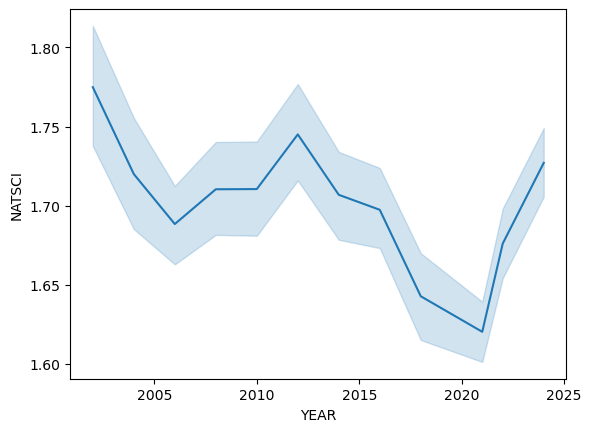

In [172]:
print("Response counts", gss['NATSCI'].value_counts().sort_index())
sns.lineplot(data=gss, x='YEAR', y='NATSCI');

## Education level
See Codebook p.219

"Respondent's education" in years of schooling
ie., 1st grade = 1, 12th grade = 12, 1 year college = 13, 4 years college = 16, etc.  Only integer values encoded, max 20.



In [173]:
gss['EDUC'].describe()

count    75413.000000
mean        13.086219
std          3.180636
min          0.000000
25%         12.000000
50%         13.000000
75%         16.000000
max         20.000000
Name: EDUC, dtype: float64

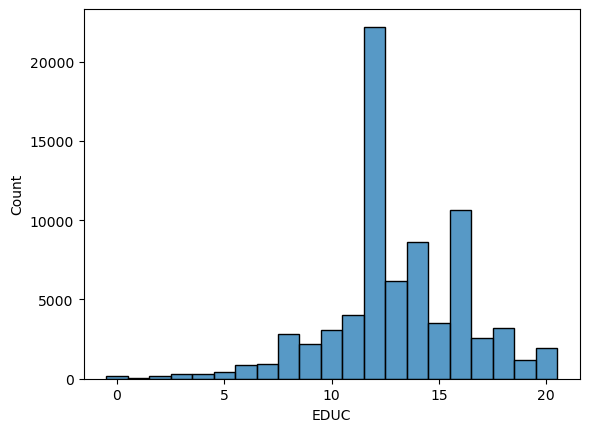

In [174]:
# use binrange to shift each whole number to the center of the bin
# if you want to understand why, comment out binrange and see the difference
sns.histplot(data=gss, x='EDUC', binwidth=1, binrange=(-0.5, 20.5));

In [175]:
# form a categorical variable 
# people who have at least some college education
gss['some_college'] = gss['EDUC']>=13
print('% of respondents with some college education: {:3.1f}'.format(gss['some_college'].sum() / gss.shape[0] * 100))

% of respondents with some college education: 50.0


/var/folders/79/k8bccz9x621gq2h0n_861kq40000gn/T/ipykernel_20761/3940661478.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  gss['some_college'] = gss['EDUC']>=13


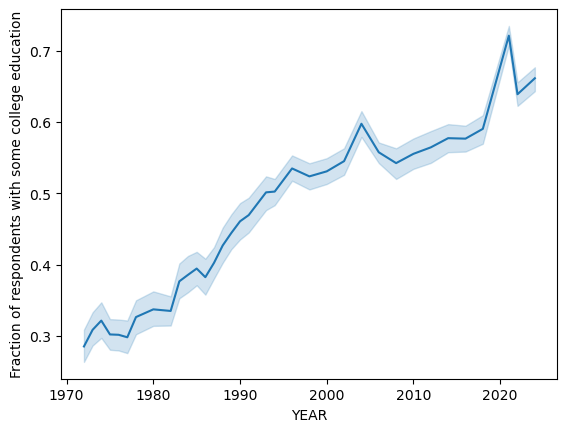

In [179]:
# does the percentage change over time?
# here we take advantage of the fact that in Python 
# False = 0 and True = 1, so using lineplot takes the average
# grouped in each year
sns.lineplot(data=gss, x='YEAR', y='some_college')
plt.ylabel('Fraction of respondents with some college education');


## Interaction of education level and opinion on science spending
 

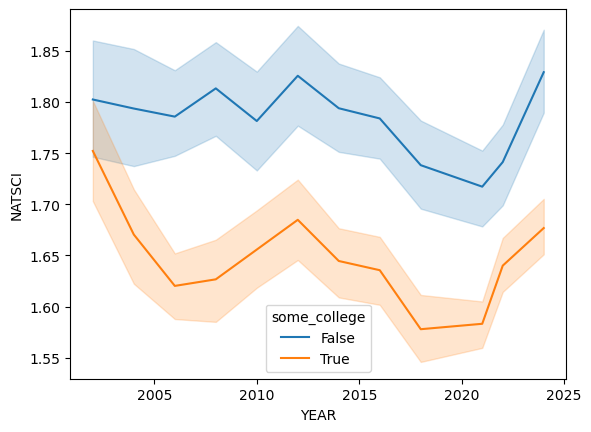

In [166]:
sns.lineplot(data=gss, x='YEAR', y='NATSCI', hue='some_college');

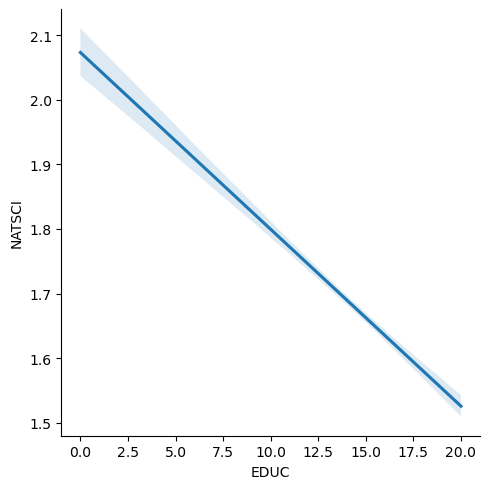

In [184]:
sns.lmplot(data=gss, x='EDUC', y='NATSCI', scatter=False);

## Conclusion

There appears to be times in the survey when all respondents were more enthusiastic to increase science spending (late 2010s) and times when they were less so (early 2000s).

Overall about half of respondents have at least some college education, but in recent decades its more like 60-70% 

There is a noticable dichotomy in the opinions of college educated vs those that are not. Both groups track the overall trends mentioned previously, but more education may equate to greater support for science funding.  

 


